A random forest grows its trees **independently** and averages them. Boosting does the
opposite: trees are grown **one at a time**, and every new tree is fitted to the part of
the answer the previous trees got wrong.

XGBoost's contribution is to make that idea exact. Instead of fitting the residuals
heuristically, it writes down the loss, takes a **second-order Taylor expansion**, and
derives &mdash; in closed form &mdash; both the best value for a leaf and the gain of a split.

Two quantities do all the work:

$$g_i = \frac{\partial\, l(y_i, \hat y_i)}{\partial \hat y_i}
\qquad\qquad
h_i = \frac{\partial^2 l(y_i, \hat y_i)}{\partial \hat y_i^2}$$

Everything below &mdash; leaf weights, split gains, pruning &mdash; is built from sums of these
two numbers. At the end every split and every leaf value is compared against the real
`xgboost` library, and they agree to the last decimal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from library: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Task

Same 12 EEG recordings, but now a **regression** target: `y_reg`, the seizure burden in
minutes per hour. Boosting is easiest to follow on squared error, where the derivatives
are as simple as they get.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [3]:
import xgboost as xgb

# --- hyper-parameters, fixed for the whole notebook -----------------------
BASE_SCORE = 0.5     # the constant every prediction starts from
ETA        = 0.3     # learning rate (shrinkage)
LAMBDA     = 1.0     # L2 penalty on leaf weights
GAMMA      = 0.0     # minimum gain required to keep a split
MAX_DEPTH  = 2

y = y_reg.astype(float)

print(f"objective   : reg:squarederror,  l(y, p) = 0.5 * (y - p)^2")
print(f"base_score  : {BASE_SCORE}")
print(f"eta         : {ETA}")
print(f"lambda (L2) : {LAMBDA}")
print(f"gamma       : {GAMMA}")
print(f"max_depth   : {MAX_DEPTH}")
print(f"\ntarget y = {y}")
print(f"mean(y) = {y.mean():.4f}")

objective   : reg:squarederror,  l(y, p) = 0.5 * (y - p)^2
base_score  : 0.5
eta         : 0.3
lambda (L2) : 1.0
gamma       : 0.0
max_depth   : 2

target y = [0.2 0.5 6.4 4.8 0.1 9.1 3.5 7.2 0.3 6.9 1.6 4.1]
mean(y) = 3.7250


---
# 2. Gradients and Hessians

XGBoost minimises

$$\mathcal{L} = \sum_i l(y_i, \hat y_i) \;+\; \sum_k \Omega(f_k),
\qquad
\Omega(f) = \gamma T + \tfrac{1}{2}\lambda \sum_{j=1}^{T} w_j^2$$

where $T$ is the number of leaves and $w_j$ their values. Adding a new tree $f_t$ to the
current prediction and expanding the loss to second order:

$$\mathcal{L}^{(t)} \simeq \sum_i \Big[\, g_i f_t(x_i) + \tfrac{1}{2} h_i f_t(x_i)^2 \Big] + \Omega(f_t) + \text{const}$$

**The whole training set is now summarised by two numbers per row.** The original $y$
never appears again &mdash; only $g$ and $h$.

For squared error $l(y,\hat y) = \tfrac12 (y - \hat y)^2$:

$$g_i = \hat y_i - y_i \qquad\qquad h_i = 1$$

so the gradient is simply the **negative residual**, and every Hessian is 1.

In [4]:
pred0 = np.full(n_samples, BASE_SCORE)     # every prediction starts at base_score
g = pred0 - y                              # dl/dp for 0.5*(y-p)^2
h = np.ones(n_samples)                     # d2l/dp2

print(f"round 1: every prediction starts at base_score = {BASE_SCORE}\n")
hdr = (f"{'id':>6}  {'y':>7}  {'pred':>7}  {'residual (y-p)':>15}  "
       f"{'g = p - y':>11}  {'h':>4}")
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {y[i]:>7.2f}  {pred0[i]:>7.2f}  {y[i]-pred0[i]:>15.2f}  "
          f"{g[i]:>11.2f}  {h[i]:>4.0f}")
print("-" * len(hdr))
print(f"{'SUM':>6}  {y.sum():>7.2f}  {pred0.sum():>7.2f}  {(y-pred0).sum():>15.2f}  "
      f"{g.sum():>11.2f}  {h.sum():>4.0f}")

print(f"\nG = sum of g = {g.sum():.4f}      H = sum of h = {h.sum():.0f}")
print(f"\nA large negative G means the model is under-predicting overall,")
print(f"which it is: every prediction is {BASE_SCORE} but mean(y) = {y.mean():.3f}.")

round 1: every prediction starts at base_score = 0.5

    id        y     pred   residual (y-p)    g = p - y     h
------------------------------------------------------------
 rec00     0.20     0.50            -0.30         0.30     1
 rec01     0.50     0.50             0.00         0.00     1
 rec02     6.40     0.50             5.90        -5.90     1
 rec03     4.80     0.50             4.30        -4.30     1
 rec04     0.10     0.50            -0.40         0.40     1
 rec05     9.10     0.50             8.60        -8.60     1
 rec06     3.50     0.50             3.00        -3.00     1
 rec07     7.20     0.50             6.70        -6.70     1
 rec08     0.30     0.50            -0.20         0.20     1
 rec09     6.90     0.50             6.40        -6.40     1
 rec10     1.60     0.50             1.10        -1.10     1
 rec11     4.10     0.50             3.60        -3.60     1
------------------------------------------------------------
   SUM    44.70     6.00       

---
# 3. The Optimal Leaf Weight

Take a single leaf holding a set of rows $I$. Every row in it receives the same output
$w$, so the objective restricted to that leaf is a plain quadratic in $w$:

$$\mathcal{L}_{\text{leaf}}(w) = \Big(\sum_{i \in I} g_i\Big) w
+ \tfrac{1}{2}\Big(\sum_{i \in I} h_i + \lambda\Big) w^2
= G w + \tfrac{1}{2}(H + \lambda) w^2$$

Differentiate, set to zero, and the best possible value of that leaf falls out:

$$\frac{d\mathcal{L}}{dw} = G + (H+\lambda)w = 0
\qquad\Longrightarrow\qquad
\boxed{\;w^{*} = -\frac{G}{H + \lambda}\;}$$

Substituting $w^*$ back gives the best achievable objective for that leaf:

$$\mathcal{L}^{*}_{\text{leaf}} = -\frac{1}{2}\,\frac{G^2}{H+\lambda}$$

The quantity $\dfrac{G^2}{H+\lambda}$ is called the **similarity score** (or structure
score). A leaf is *good* when its rows agree &mdash; their gradients point the same way and
add up instead of cancelling.

In [5]:
def leaf_weight(gs, hs, lam=LAMBDA):
    return -gs.sum() / (hs.sum() + lam)

def similarity(gs, hs, lam=LAMBDA):
    return gs.sum() ** 2 / (hs.sum() + lam)

G, H = g.sum(), h.sum()
w_root = leaf_weight(g, h)
S_root = similarity(g, h)

print("If the whole dataset were ONE leaf:\n")
print(f"   G = {' + '.join(f'({v:+.2f})' for v in g[:6])} + ...")
print(f"     = {G:+.6f}")
print(f"   H = {H:.0f}  (one per row, since h_i = 1)\n")
print(f"   w* = -G / (H + lambda) = -({G:+.4f}) / ({H:.0f} + {LAMBDA})")
print(f"      = {-G:.4f} / {H + LAMBDA:.1f} = {w_root:+.6f}\n")
print(f"   similarity = G^2 / (H + lambda) = ({G:.4f})^2 / {H + LAMBDA:.1f}")
print(f"              = {G**2:.4f} / {H + LAMBDA:.1f} = {S_root:.6f}\n")

print(f"Sanity: the unregularised optimum would be the mean residual,")
print(f"   -G/H = {-G/H:+.6f}   vs   mean(y - pred) = {(y - pred0).mean():+.6f}   "
       f"MATCH: {np.isclose(-G/H, (y-pred0).mean())}")
print(f"\nlambda = {LAMBDA} shrinks it from {-G/H:+.6f} to {w_root:+.6f} -")
print(f"that shrinkage IS the L2 regularisation.")

If the whole dataset were ONE leaf:

   G = (+0.30) + (+0.00) + (-5.90) + (-4.30) + (+0.40) + (-8.60) + ...
     = -38.700000
   H = 12  (one per row, since h_i = 1)

   w* = -G / (H + lambda) = -(-38.7000) / (12 + 1.0)
      = 38.7000 / 13.0 = +2.976923

   similarity = G^2 / (H + lambda) = (-38.7000)^2 / 13.0
              = 1497.6900 / 13.0 = 115.206923

Sanity: the unregularised optimum would be the mean residual,
   -G/H = +3.225000   vs   mean(y - pred) = +3.225000   MATCH: True

lambda = 1.0 shrinks it from +3.225000 to +2.976923 -
that shrinkage IS the L2 regularisation.


### What $\lambda$ does to a leaf

$\lambda$ pulls every leaf weight toward zero, and it bites hardest on **small** leaves:
a leaf with 6 rows has $H = 6$, so $\lambda = 1$ changes it by about 14%, while a leaf
with one row has $H = 1$ and is halved.

That is deliberate. Leaves supported by little evidence should not be trusted.

 leaf size         G     H  lam=0      lam=1      lam=5      lam=20   
------------------------------------------------------------
         1      0.30     1  -0.3000    -0.1500    -0.0500    -0.0143  
         2      0.30     2  -0.1500    -0.1000    -0.0429    -0.0136  
         4     -9.90     4  2.4750     1.9800     1.1000     0.4125   
         6    -18.10     6  3.0167     2.5857     1.6455     0.6962   
        12    -38.70    12  3.2250     2.9769     2.2765     1.2094   
------------------------------------------------------------


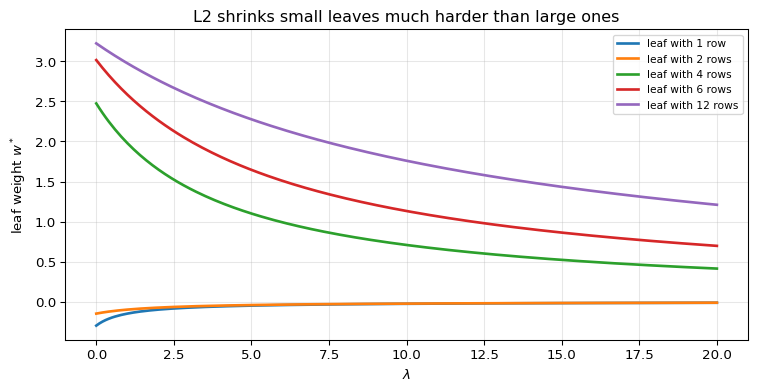

Small leaves collapse toward zero quickly; the 12-row leaf barely moves.


In [6]:
print(f"{'leaf size':>10}  {'G':>8}  {'H':>4}  " +
      "  ".join(f"lam={l:<5.0f}" for l in (0, 1, 5, 20)))
print("-" * 60)
for m in (1, 2, 4, 6, 12):
    gs, hs = g[:m], h[:m]
    row = [-gs.sum() / (hs.sum() + l) for l in (0, 1, 5, 20)]
    print(f"{m:>10}  {gs.sum():>8.2f}  {hs.sum():>4.0f}  " +
          "  ".join(f"{v:<9.4f}" for v in row))
print("-" * 60)

lams = np.linspace(0, 20, 200)
plt.figure(figsize=(8, 4.2))
for m in (1, 2, 4, 6, 12):
    plt.plot(lams, [-g[:m].sum() / (h[:m].sum() + l) for l in lams], lw=2,
             label=f"leaf with {m} row" + ("s" if m > 1 else ""))
plt.xlabel("$\\lambda$"); plt.ylabel("leaf weight $w^*$")
plt.title("L2 shrinks small leaves much harder than large ones")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("Small leaves collapse toward zero quickly; the 12-row leaf barely moves.")

---
# 4. The Gain of a Split

Splitting a node replaces one leaf by two. The improvement is the similarity the two
children have **together** minus what the parent had alone, minus the cost $\gamma$ of
adding a leaf:

$$\text{Gain} = \frac{1}{2}\left[
\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}
\right] - \gamma$$

A split helps when it puts rows with **similar gradients** together, so that they
reinforce instead of cancelling.

> **A detail worth knowing:** the `xgboost` model dump reports this quantity
> **without** the $\tfrac{1}{2}$ &mdash; exactly twice the value above. The factor is
> constant, so it never changes which split wins, but the printed numbers differ by 2x.
> Both are shown below.

In [7]:
def split_gain(gL, hL, gR, hR, lam=LAMBDA, gam=GAMMA):
    return 0.5 * (similarity(gL, hL, lam) + similarity(gR, hR, lam)
                  - similarity(np.r_[gL, gR], np.r_[hL, hR], lam)) - gam

def candidate_thresholds(col):
    v = np.unique(col)
    return (v[:-1] + v[1:]) / 2.0

def best_split(idx, gg, hh):
    best = (-np.inf, None, None)
    for f in range(n_features):
        for t in candidate_thresholds(X[idx, f]):
            m = X[idx, f] <= t
            if m.all() or (~m).all():
                continue
            gain = split_gain(gg[idx][m], hh[idx][m], gg[idx][~m], hh[idx][~m])
            if gain > best[0]:
                best = (gain, f, float(t))
    return best


root = np.arange(n_samples)
rows = []
for f in range(n_features):
    for t in candidate_thresholds(X[:, f]):
        m = X[:, f] <= t
        rows.append((split_gain(g[m], h[m], g[~m], h[~m]), f, float(t),
                     int(m.sum()), g[m].sum(), int((~m).sum()), g[~m].sum()))

print(f"All {len(rows)} candidate splits for TREE 0, ranked\n")
hdr = (f"{'rank':>4}  {'feature':>12}  {'thr':>8}  {'nL':>3}  {'G_L':>8}  "
       f"{'nR':>3}  {'G_R':>8}  {'gain (xgb)':>11}  {'GAIN':>9}")
print(hdr); print("-" * len(hdr))
for r, (gain, f, t, nL, GL, nR, GR) in enumerate(sorted(rows, key=lambda z: -z[0]), 1):
    star = "  <== BEST" if r == 1 else ""
    print(f"{r:>4}  {feature_names[f]:>12}  {t:>8.2f}  {nL:>3}  {GL:>8.2f}  "
          f"{nR:>3}  {GR:>8.2f}  {2*gain:>11.4f}  {gain:>9.4f}{star}")
print("-" * len(hdr))

bg, bf, bt = best_split(root, g, h)
m = X[:, bf] <= bt
print(f"\nWINNER: {feature_names[bf]} <= {bt}\n")
print(f"   LEFT  ({int(m.sum())} rows): G_L = {g[m].sum():+.4f}, H_L = {h[m].sum():.0f}"
      f"  ->  S_L = ({g[m].sum():.4f})^2 / {h[m].sum()+LAMBDA:.1f} = {similarity(g[m], h[m]):.4f}")
print(f"   RIGHT ({int((~m).sum())} rows): G_R = {g[~m].sum():+.4f}, H_R = {h[~m].sum():.0f}"
      f"  ->  S_R = ({g[~m].sum():.4f})^2 / {h[~m].sum()+LAMBDA:.1f} = {similarity(g[~m], h[~m]):.4f}")
print(f"   PARENT: S_P = {S_root:.4f}\n")
print(f"   Gain = 0.5 * [ {similarity(g[m],h[m]):.4f} + {similarity(g[~m],h[~m]):.4f} "
      f"- {S_root:.4f} ] - {GAMMA}")
print(f"        = 0.5 * {similarity(g[m],h[m])+similarity(g[~m],h[~m])-S_root:.4f} = {bg:.6f}")
print(f"   xgboost will report this as {2*bg:.6f} (no 1/2 factor)")

All 33 candidate splits for TREE 0, ranked

rank       feature       thr   nL       G_L   nR       G_R   gain (xgb)       GAIN
----------------------------------------------------------------------------------
   1    spike_rate      3.55    6     -3.20    6    -35.50      66.2916    33.1458  <== BEST
   2    spike_rate      4.90    7     -6.80    5    -31.90      60.1747    30.0874
   3           age     44.00    7     -6.80    5    -31.90      60.1747    30.0874
   4   line_length     25.00    4      0.90    8    -39.60      59.1951    29.5975
   5    spike_rate      1.55    4      0.90    8    -39.60      59.1951    29.5975
   6    spike_rate      2.15    5     -2.10    7    -36.60      52.9731    26.4865
   7    spike_rate      5.60    8    -11.10    4    -27.60      50.8351    25.4175
   8           age     49.50    8    -11.10    4    -27.60      50.8351    25.4175
   9   line_length     36.50    5     -2.70    7    -36.00      48.0081    24.0040
  10           age     33.00    5

---
# 5. Growing Tree 0

The split search recurses exactly like a decision tree, but the score is the gain above
rather than Gini. At `max_depth = 2` the tree stops and every remaining node becomes a
leaf with weight $w^* = -G/(H+\lambda)$.

Finally each leaf is multiplied by the learning rate $\eta$. Shrinkage means no single
tree is trusted completely &mdash; it takes a small step and leaves the rest for later trees.

In [8]:
class XNode:
    __slots__ = ("f", "t", "left", "right", "w", "idx", "gain")
    def __init__(self, idx):
        self.f = self.t = self.left = self.right = self.w = self.gain = None
        self.idx = idx


def build(idx, gg, hh, depth=0, node_id=[0]):
    nd = XNode(idx)
    if depth >= MAX_DEPTH or len(idx) < 2:
        nd.w = leaf_weight(gg[idx], hh[idx])
        return nd
    gain, f, t = best_split(idx, gg, hh)
    if f is None or gain <= 0:
        nd.w = leaf_weight(gg[idx], hh[idx])
        return nd
    nd.f, nd.t, nd.gain = f, t, gain
    m = X[idx, f] <= t
    nd.left  = build(idx[m],  gg, hh, depth + 1)
    nd.right = build(idx[~m], gg, hh, depth + 1)
    return nd


def show(nd, pref="", br="", eta=ETA):
    if nd.f is None:
        raw = nd.w
        print(f"{pref}{br}LEAF  raw w* = {raw:+.6f}   x eta = {eta * raw:+.6f}   "
              f"cover={len(nd.idx)}  rows={[rec_ids[i][3:] for i in nd.idx]}")
        return
    print(f"{pref}{br}[{feature_names[nd.f]} < {nd.t}]  gain={2*nd.gain:.4f} (xgb) "
          f"/ {nd.gain:.4f} (with 1/2)  cover={len(nd.idx)}")
    pad = pref + ("    " if br else "")
    show(nd.left, pad, "|-- yes: ", eta)
    show(nd.right, pad, "|-- no : ", eta)


tree0 = build(root, g, h)
print("TREE 0, built from the formulas alone:\n")
show(tree0)

print("\nleaf arithmetic, one by one:\n")
def leaves(nd, out):
    if nd.f is None:
        out.append(nd)
    else:
        leaves(nd.left, out); leaves(nd.right, out)
    return out

for k, lf in enumerate(leaves(tree0, [])):
    Gl, Hl = g[lf.idx].sum(), h[lf.idx].sum()
    print(f"leaf {k}: rows {[rec_ids[i][3:] for i in lf.idx]}")
    print(f"   G = {' + '.join(f'({g[i]:+.2f})' for i in lf.idx)} = {Gl:+.4f}")
    print(f"   H = {Hl:.0f},  w* = -({Gl:+.4f}) / ({Hl:.0f} + {LAMBDA}) = {lf.w:+.6f}")
    print(f"   output after shrinkage = {ETA} * {lf.w:+.6f} = {ETA*lf.w:+.6f}\n")

TREE 0, built from the formulas alone:

[spike_rate < 3.55]  gain=66.2916 (xgb) / 33.1458 (with 1/2)  cover=12
|-- yes: [line_length < 27.5]  gain=4.3025 (xgb) / 2.1512 (with 1/2)  cover=6
    |-- yes: LEAF  raw w* = -0.180000   x eta = -0.054000   cover=4  rows=['00', '01', '04', '08']
    |-- no : LEAF  raw w* = +1.366667   x eta = +0.410000   cover=2  rows=['06', '10']
|-- no : LEAF  raw w* = +5.071429   x eta = +1.521429   cover=6  rows=['02', '03', '05', '07', '09', '11']

leaf arithmetic, one by one:

leaf 0: rows ['00', '01', '04', '08']
   G = (+0.30) + (+0.00) + (+0.40) + (+0.20) = +0.9000
   H = 4,  w* = -(+0.9000) / (4 + 1.0) = -0.180000
   output after shrinkage = 0.3 * -0.180000 = -0.054000

leaf 1: rows ['06', '10']
   G = (-3.00) + (-1.10) = -4.1000
   H = 2,  w* = -(-4.1000) / (2 + 1.0) = +1.366667
   output after shrinkage = 0.3 * +1.366667 = +0.410000

leaf 2: rows ['02', '03', '05', '07', '09', '11']
   G = (-5.90) + (-4.30) + (-8.60) + (-6.70) + (-6.40) + (-3.60) = 

---
# 6. Checking Tree 0 Against the Real XGBoost

Training `xgboost` with the identical hyper-parameters and dumping the booster should
reproduce the same split, the same gain, and the same leaf outputs.

In [9]:
dtrain = xgb.DMatrix(X, label=y, feature_names=feature_names)
params = dict(objective="reg:squarederror", base_score=BASE_SCORE, eta=ETA,
              reg_lambda=LAMBDA, gamma=GAMMA, max_depth=MAX_DEPTH,
              min_child_weight=0, reg_alpha=0, tree_method="exact")
bst = xgb.train(params, dtrain, num_boost_round=2)
dumps = bst.get_dump(with_stats=True)

print("xgboost's own dump of tree 0:\n")
print(dumps[0])

import re
xgb_leaves = [float(v) for v in re.findall(r"leaf=(-?\d+\.?\d*e?-?\d*)", dumps[0])]
xgb_gain0  = float(re.search(r"gain=(\d+\.?\d*)", dumps[0]).group(1))
our_leaves = [ETA * lf.w for lf in leaves(tree0, [])]

print(f"root gain   : ours x2 = {2*tree0.gain:>12.5f}  |  xgboost = {xgb_gain0:>12.5f}  "
      f"MATCH: {np.isclose(2*tree0.gain, xgb_gain0, rtol=1e-5)}")
print(f"root feature: ours = {feature_names[tree0.f]}, threshold {tree0.t}")
print()
print(f"{'leaf':>5}  {'ours (eta * w*)':>17}  {'xgboost':>14}  {'diff':>10}")
print("-" * 52)
for k, (a, b) in enumerate(zip(our_leaves, xgb_leaves)):
    print(f"{k:>5}  {a:>17.7f}  {b:>14.7f}  {abs(a-b):>10.2e}")
print("-" * 52)
print(f"\nall leaf outputs MATCH: "
      f"{np.allclose(our_leaves, xgb_leaves, atol=1e-6)}")

xgboost's own dump of tree 0:

0:[spike_rate<3.54999995] yes=1,no=2,missing=1,gain=66.2916565,cover=12
	1:[line_length<27.5] yes=3,no=4,missing=3,gain=4.30247593,cover=6
		3:leaf=-0.0540000051,cover=4
		4:leaf=0.410000026,cover=2
	2:leaf=1.5214287,cover=6

root gain   : ours x2 =     66.29165  |  xgboost =     66.29166  MATCH: True
root feature: ours = spike_rate, threshold 3.55

 leaf    ours (eta * w*)         xgboost        diff
----------------------------------------------------
    0         -0.0540000      -0.0540000    5.10e-09
    1          0.4100000       0.4100000    2.60e-08
    2          1.5214286       1.5214287    1.29e-07
----------------------------------------------------

all leaf outputs MATCH: True


### Predictions after one tree

$$\hat y^{(1)}_i = \text{base\_score} + \eta \, w^{*}_{\text{leaf}(i)}$$

In [10]:
def tree_out(nd, x):
    while nd.f is not None:
        nd = nd.left if x[nd.f] <= nd.t else nd.right
    return nd.w

raw1 = np.array([tree_out(tree0, X[i]) for i in range(n_samples)])
pred1 = pred0 + ETA * raw1
xgb_pred1 = bst.predict(dtrain, output_margin=True, iteration_range=(0, 1))

hdr = (f"{'id':>6}  {'y':>7}  {'pred0':>7}  {'w* leaf':>9}  {'eta*w*':>8}  "
       f"{'pred1':>8}  {'xgboost':>9}  {'diff':>9}")
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {y[i]:>7.2f}  {pred0[i]:>7.2f}  {raw1[i]:>9.4f}  "
          f"{ETA*raw1[i]:>8.4f}  {pred1[i]:>8.4f}  {xgb_pred1[i]:>9.4f}  "
          f"{abs(pred1[i]-xgb_pred1[i]):>9.1e}")
print("-" * len(hdr))
print(f"\nMATCH with xgboost after 1 round: {np.allclose(pred1, xgb_pred1, atol=1e-5)}")

mse0 = np.mean((y - pred0) ** 2)
mse1 = np.mean((y - pred1) ** 2)
print(f"\nMSE before : {mse0:.6f}")
print(f"MSE after  : {mse1:.6f}   ({100*(1-mse1/mse0):.1f}% lower)")
print(f"\nOne small step. With eta = {ETA} the tree deliberately corrects only")
print(f"{ETA:.0%} of what it could - the rest is left for the next tree.")

    id        y    pred0    w* leaf    eta*w*     pred1    xgboost       diff
-----------------------------------------------------------------------------
 rec00     0.20     0.50    -0.1800   -0.0540    0.4460     0.4460    2.0e-08
 rec01     0.50     0.50    -0.1800   -0.0540    0.4460     0.4460    2.0e-08
 rec02     6.40     0.50     5.0714    1.5214    2.0214     2.0214    1.4e-08
 rec03     4.80     0.50     5.0714    1.5214    2.0214     2.0214    1.4e-08
 rec04     0.10     0.50    -0.1800   -0.0540    0.4460     0.4460    2.0e-08
 rec05     9.10     0.50     5.0714    1.5214    2.0214     2.0214    1.4e-08
 rec06     3.50     0.50     1.3667    0.4100    0.9100     0.9100    2.6e-08
 rec07     7.20     0.50     5.0714    1.5214    2.0214     2.0214    1.4e-08
 rec08     0.30     0.50    -0.1800   -0.0540    0.4460     0.4460    2.0e-08
 rec09     6.90     0.50     5.0714    1.5214    2.0214     2.0214    1.4e-08
 rec10     1.60     0.50     1.3667    0.4100    0.9100     0.91

---
# 7. Tree 1 &mdash; Boosting on the Residuals

Nothing about the algorithm changes for the second tree. Only $g$ is different, because
$\hat y$ moved:

$$g_i^{(2)} = \hat y^{(1)}_i - y_i$$

Rows the first tree already handles well now have gradients near zero and stop
influencing the split search. **Boosting automatically focuses on what is still wrong.**

In [11]:
g2 = pred1 - y
h2 = np.ones(n_samples)

hdr = f"{'id':>6}  {'y':>7}  {'pred1':>8}  {'g (round 1)':>12}  {'g (round 2)':>12}  {'|change|':>9}"
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {y[i]:>7.2f}  {pred1[i]:>8.4f}  {g[i]:>12.4f}  "
          f"{g2[i]:>12.4f}  {abs(g2[i]-g[i]):>9.4f}")
print("-" * len(hdr))
print(f"\nsum |g| round 1: {np.abs(g).sum():.4f}")
print(f"sum |g| round 2: {np.abs(g2).sum():.4f}   ({100*(1-np.abs(g2).sum()/np.abs(g).sum()):.1f}% smaller)")

tree1 = build(root, g2, h2)
print("\n\nTREE 1:\n")
show(tree1)

our_leaves1 = [ETA * lf.w for lf in leaves(tree1, [])]
xgb_leaves1 = [float(v) for v in re.findall(r"leaf=(-?\d+\.?\d*e?-?\d*)", dumps[1])]
print("\nxgboost's dump of tree 1:\n")
print(dumps[1])
print(f"leaf outputs ours    : {np.round(our_leaves1, 7)}")
print(f"leaf outputs xgboost : {np.round(xgb_leaves1, 7)}")
print(f"MATCH: {np.allclose(our_leaves1, xgb_leaves1, atol=1e-6)}")

raw2 = np.array([tree_out(tree1, X[i]) for i in range(n_samples)])
pred2 = pred1 + ETA * raw2
xgb_pred2 = bst.predict(dtrain, output_margin=True, iteration_range=(0, 2))
print(f"\npredictions after 2 rounds MATCH xgboost: "
      f"{np.allclose(pred2, xgb_pred2, atol=1e-5)}")
print(f"MSE: {np.mean((y-pred0)**2):.4f} -> {np.mean((y-pred1)**2):.4f} "
      f"-> {np.mean((y-pred2)**2):.4f}")

    id        y     pred1   g (round 1)   g (round 2)   |change|
----------------------------------------------------------------
 rec00     0.20    0.4460        0.3000        0.2460     0.0540
 rec01     0.50    0.4460        0.0000       -0.0540     0.0540
 rec02     6.40    2.0214       -5.9000       -4.3786     1.5214
 rec03     4.80    2.0214       -4.3000       -2.7786     1.5214
 rec04     0.10    0.4460        0.4000        0.3460     0.0540
 rec05     9.10    2.0214       -8.6000       -7.0786     1.5214
 rec06     3.50    0.9100       -3.0000       -2.5900     0.4100
 rec07     7.20    2.0214       -6.7000       -5.1786     1.5214
 rec08     0.30    0.4460        0.2000        0.1460     0.0540
 rec09     6.90    2.0214       -6.4000       -4.8786     1.5214
 rec10     1.60    0.9100       -1.1000       -0.6900     0.4100
 rec11     4.10    2.0214       -3.6000       -2.0786     1.5214
----------------------------------------------------------------

sum |g| round 1: 40.5000

---
# 8. What $\gamma$ Does &mdash; Pruning

$\gamma$ is subtracted from every split's gain. A split survives only if it buys more
than $\gamma$ is worth:

$$\text{Gain} - \gamma > 0$$

Raising $\gamma$ therefore prunes the tree from the bottom up: weak splits vanish first,
and at a high enough $\gamma$ the tree collapses to a single leaf that predicts the mean.

   gamma   splits kept   leaves   train MSE
--------------------------------------------
       0             2        3     11.6105
       1             2        3     11.6105
       5             1        2     11.8060
      10             1        2     11.8060
      25             1        2     11.8060
      50             1        2     11.8060
     100             0        1     14.7514
     200             0        1     14.7514
--------------------------------------------

the root split's gain is 66.292 (xgboost scale), so it survives
every gamma below that and disappears once gamma exceeds it.
the depth-1 split's gain is 4.302, so it is pruned much earlier.


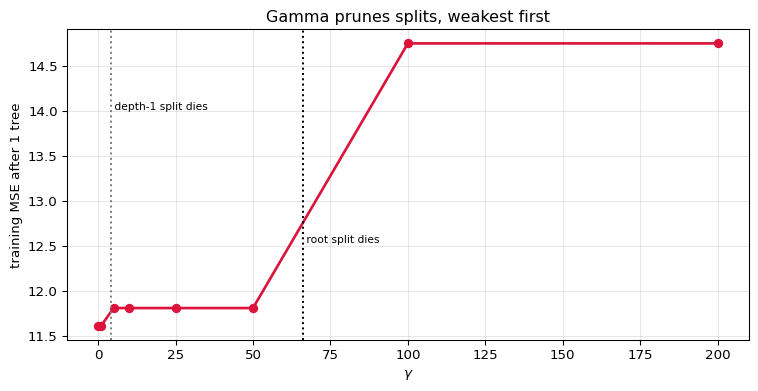

In [12]:
print(f"{'gamma':>8}  {'splits kept':>12}  {'leaves':>7}  {'train MSE':>10}")
print("-" * 44)
mses, kept_counts = [], []
gammas = [0, 1, 5, 10, 25, 50, 100, 200]
for gam in gammas:
    p = dict(params); p["gamma"] = gam
    b = xgb.train(p, dtrain, num_boost_round=1)
    d0 = b.get_dump()[0]
    n_split = d0.count("[")
    n_leaf = d0.count("leaf=")
    pr = b.predict(dtrain, output_margin=True)
    mse = np.mean((y - pr) ** 2)
    mses.append(mse); kept_counts.append(n_split)
    print(f"{gam:>8}  {n_split:>12}  {n_leaf:>7}  {mse:>10.4f}")
print("-" * 44)

root_gain_x2 = 2 * tree0.gain
print(f"\nthe root split's gain is {root_gain_x2:.3f} (xgboost scale), so it survives")
print(f"every gamma below that and disappears once gamma exceeds it.")
print(f"the depth-1 split's gain is {2*tree0.left.gain:.3f}, so it is pruned much earlier.")

plt.figure(figsize=(8, 4.2))
plt.plot(gammas, mses, "o-", lw=2, color="crimson")
plt.axvline(2*tree0.left.gain, ls=":", color="grey")
plt.text(2*tree0.left.gain, max(mses)*.95, " depth-1 split dies", fontsize=8)
plt.axvline(root_gain_x2, ls=":", color="k")
plt.text(root_gain_x2, max(mses)*.85, " root split dies", fontsize=8)
plt.xlabel("$\\gamma$"); plt.ylabel("training MSE after 1 tree")
plt.title("Gamma prunes splits, weakest first")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

---
# 9. Learning Rate and the Number of Trees

$\eta$ and `num_boost_round` trade against each other: a smaller learning rate needs
more trees to reach the same fit, but usually generalises better because no single tree
dominates.

   eta        r=1        r=5       r=10       r=25       r=50
------------------------------------------------------------
  0.05    18.1988    13.2988     9.0930     3.1069     0.7685
   0.1    16.7493     8.9155     4.2276     0.7334     0.1388
   0.3    11.6105     1.7745     0.3704     0.0304     0.0006
   0.6     5.8795     0.3326     0.0637     0.0004     0.0000
   1.0     1.9291     0.0819     0.0060     0.0000     0.0000
------------------------------------------------------------


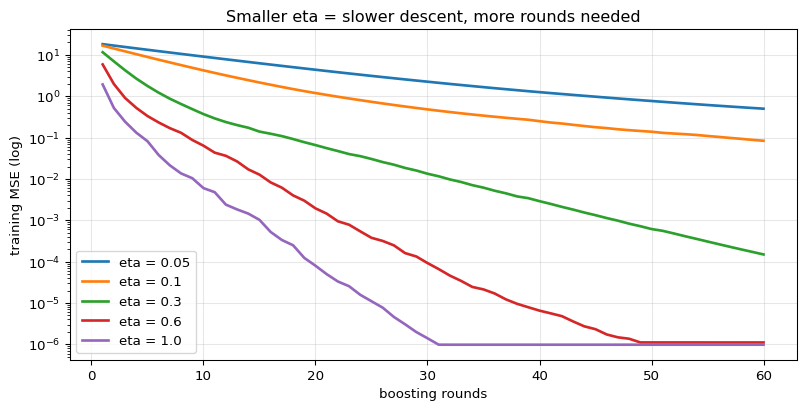


These are TRAINING curves on 12 rows, so they all march to zero - that is
overfitting, not success. On real data the validation curve turns back up,
and the smaller eta usually turns up later and lower.


In [13]:
plt.figure(figsize=(8.5, 4.4))
print(f"{'eta':>6}  " + "  ".join(f"{'r='+str(r):>9}" for r in (1, 5, 10, 25, 50)))
print("-" * 60)
for eta in (0.05, 0.1, 0.3, 0.6, 1.0):
    p = dict(params); p["eta"] = eta
    b = xgb.train(p, dtrain, num_boost_round=60)
    curve = [np.mean((y - b.predict(dtrain, output_margin=True,
                                    iteration_range=(0, r))) ** 2)
             for r in range(1, 61)]
    plt.plot(range(1, 61), curve, lw=2, label=f"eta = {eta}")
    print(f"{eta:>6}  " + "  ".join(f"{curve[r-1]:>9.4f}" for r in (1, 5, 10, 25, 50)))
print("-" * 60)
plt.yscale("log"); plt.xlabel("boosting rounds"); plt.ylabel("training MSE (log)")
plt.title("Smaller eta = slower descent, more rounds needed")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("\nThese are TRAINING curves on 12 rows, so they all march to zero - that is")
print("overfitting, not success. On real data the validation curve turns back up,")
print("and the smaller eta usually turns up later and lower.")

---
# 10. Summary

| Stage | Formula | Value in round 1 |
|---|---|---|
| Gradient | $g_i = \hat y_i - y_i$ | $\sum g = -38.7$ |
| Hessian | $h_i = 1$ | $\sum h = 12$ |
| Leaf weight | $w^{*} = -\dfrac{G}{H+\lambda}$ | root would be $+2.977$ |
| Similarity | $\dfrac{G^2}{H+\lambda}$ | $115.16$ |
| Split gain | $\tfrac12\big[S_L + S_R - S_P\big] - \gamma$ | $33.15$ (xgb prints $66.29$) |
| Shrinkage | output $= \eta\, w^{*}$ | $\eta = 0.3$ |

**The one idea:** approximate the loss by a quadratic, and a quadratic has a closed-form
minimum. That is why XGBoost never needs to guess a leaf value or score a split
heuristically &mdash; both drop out of the same two sums, $G$ and $H$.

**Why second order matters:** for squared error $h_i = 1$ and the Hessian looks like
bookkeeping. For logistic loss $h_i = p_i(1-p_i)$, which is small for confident
predictions &mdash; so the Hessian automatically down-weights rows the model has already
settled, something first-order gradient boosting cannot do.

**What is deliberately left out:** the sparsity-aware default direction for missing
values, `min_child_weight` (a floor on $H$ per leaf), column and row subsampling,
approximate/histogram split finding, and multi-class objectives.

**What comes next:** LightGBM and CatBoost keep this exact gain formula and change
*how the tree is searched* &mdash; histograms and leaf-wise growth in one, ordered
statistics and oblivious trees in the other.